# Introdução às Redes Neurais e Deep Learning

## Gated Recurrent Unit (GRU)

As GRUs são uma versão simplificada das LSTMs que utilizam portas de atualização e de redefinição para aprender dependências de longo prazo de maneira eficiente. Suas principais características são: 

* Simplificação da arquitetura LSTM.
* Utilização de apenas duas portas: Reset Gate e Update Gate.
* Ausência de um estado de célula separado $C_t$.
* Menor número de parâmetros para a mesma dimensão do estado oculto.
* Capacidade de aprender dependências temporais de longo prazo.

<table>
    <tr>
      <td>
      <img src='Files/LSTMcomGRU.jpg'width=400>
      </td>
      <td>
      <img src='Files/GRUcompLSTM.jpg'width=400>
      </td>
     </tr>
</table>

### Comparação entre LSTM e GRU

| Característica | LSTM | GRU |
|---|---|---|
| Denominação | Long Short-Term Memory | Gated Recurrent Unit |
| Ano de introdução | 1997 | 2014 |
| Número de portas | 3 | 2 |
| Forget Gate (porta de esquecimento) | Sim | Não |
| Input Gate (porta de entrada) | Sim | Não |
| Output Gate (porta de saída) | Sim | Não |
| Reset Gate (porta de reinicialização) | Não | Sim |
| Update Gate (porta de atualização) | Não | Sim |
| Estado oculto $h_t$ | Sim | Sim |
| Estado da célula $C_t$ | Sim | Não |
| Controle independente da saída | Sim | Não |
| Complexidade estrutural | Maior | Menor |
| Número de parâmetros | Maior | Menor |
| Custo computacional teórico | Maior | Menor |
| Tempo de treinamento | Geralmente maior | Potencialmente menor |
| Mitigação do vanishing gradient | Sim | Sim |
| Aprendizado de dependências de longo prazo | Sim | Sim |
| Desempenho preditivo | Dependente da aplicação | Dependente da aplicação |

A GRU pode ser considerada uma alternativa estruturalmente mais simples à LSTM. A porta de atualização (*Update Gate*) reúne parcialmente as funções desempenhadas pelas portas de entrada e de esquecimento da LSTM. Além disso, a GRU não possui um estado de célula independente, utilizando apenas o estado oculto para armazenar e transmitir informações ao longo do tempo.

Essa simplificação resulta em um menor número de parâmetros treináveis e em uma redução do custo computacional teórico, considerando as mesmas dimensões de entrada e do estado oculto. Entretanto, isso não significa necessariamente um desempenho preditivo inferior ou superior ao da LSTM. A escolha entre as duas arquiteturas depende das características do problema e deve, preferencialmente, ser fundamentada em resultados experimentais.

### Equacionamento básico

$$ r_t=\sigma(W_rx_t+U_rh_{t-1}+b_r)$$

$$z_t=\sigma(W_zx_t+U_zh_{t-1}+b_z)$$

$$\widetilde h_t=\tanh\left(W_hx_t+r_t\otimes(U_hh_{t-1}+b_{h,r})+b_{h,x}\right)$$

$$\boxed{h_t=z_t\otimes h_{t-1}+(1-z_t)\otimes\widetilde h_t}$$

### Comparação pelo número de parâmetros

1) LSTM:
  A camada LSTM terá $N_{LSTM}$ parâmetros, onde:
$$ \boxed{N_{\mathrm{LSTM}}=4n_h(n_x+n_h+1)},$$

e 
* $n_x$: dimensão do vetor de entrada (vocabulário),

* $n_h$: dimensão do estado oculto,

* O fator 4 corresponde às três portas e ao estado candidato da célula, e
a
* O termo $+1$ corresponde aos biases.

  A soma $n_x+n_h$ deve-se à concatenação $z_t=\begin{bmatrix}h_{t-1}\\x_t\end{bmatrix}$.

2) GRU:
   Na GRU temos duas portas e um estado candidato. Entretanto, a implementação padrão do Keras (reset_after=True) utiliza dois conjuntos de biases: um associado à entrada e outro associado ao estado recorrente. Daí,
$$\boxed{N_{\mathrm{GRU}}=3n_h(n_x+n_h+2)}$$

No exemplo da aula anterior (dataset formado por um conjunto de diferentes poemas) que será repetido aqui, temos $n_x=35$ e $ n_h=128$, de forma que $N_{LSTM}=83968$ e $N_{GRU}=63360$, uma redução de $24,54\%$. Além disso, se considerarmos as camadas densas nas dua redes, $N_{\mathrm{Dense}}=n_y(n_h+1)=35\times(128+1)=4.515$. Finalmente as duas redes terão 88483 e 67875 parâmetros, respectivamente. 

### Geração de texto usando GRU a partir de um *dataset* formado por um conjunto de diferentes poemas

#### Importação das bibliotecas

In [2]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

import pandas as pd
import numpy as np
import random

#### Leitura do *dataset*

In [3]:
df = pd.read_csv('Files/poems.csv', header=None, names=['text'])
text = " ".join(df['text'].tolist())

#### Identificação do conjunto de caracteres (tokens) únicos na base de dados, criação de sequências de comprimento fixo e dos respectivos rótulos, e a codificação da entrada e dos rótulos em vetores *One-Hot*:

In [4]:
vocab = sorted(set(text))
char_to_index = {c: i for i, c in enumerate(vocab)}
index_to_char = {i: c for i, c in enumerate(vocab)}

seq_length = 100

step = 5 # O parâmetro step determina o deslocamento da janela durante a construção dos exemplos de treinamento.

sequences = []
labels = []

for i in range(0, len(text) - seq_length, step):
    seq = text[i:i + seq_length]
    label = text[i + seq_length]

    sequences.append([char_to_index[c] for c in seq])
    labels.append(char_to_index[label])

X = np.array(sequences)
y = np.array(labels)

X = to_categorical(X, num_classes=len(vocab))
y = to_categorical(y, num_classes=len(vocab))

#### Criação do  modelo GRU

In [5]:
model = Sequential([
    Input(shape=(seq_length, len(vocab))),
    GRU(128, activation='tanh'),
    Dense(len(vocab), activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy'
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 128)                 │          63,360 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 35)                  │           4,515 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 67,875 (265.14 KB)

 Trainable params: 67,875 (265.14 KB)

 Non-trainable params: 0 (0.00 B)

#### Treinamento e avaliação do tempo computacional

In [6]:
import time

inicio = time.perf_counter()

history_gru = model.fit(
    X, y,
    epochs=30,
    batch_size=128
)

fim = time.perf_counter()

tempo_gru = fim - inicio

print(f"Tempo total: {tempo_gru:.2f} s")
print(f"Tempo por época: {tempo_gru/30:.2f} s")

model.save('Files/modelo_GRU.keras')

Epoch 1/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 108s 77ms/step - loss: 1.8500
Epoch 2/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 107s 77ms/step - loss: 0.0666
Epoch 3/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 105s 75ms/step - loss: 0.0524
Epoch 4/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 103s 74ms/step - loss: 0.0490
Epoch 5/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 104s 75ms/step - loss: 0.0485
Epoch 6/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 104s 75ms/step - loss: 0.0525
Epoch 7/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 103s 74ms/step - loss: 0.0476
Epoch 8/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 103s 74ms/step - loss: 0.0472
Epoch 9/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 103s 74ms/step - loss: 0.0467
Epoch 10/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 102s 74ms/step - loss: 0.0486
Epoch 11/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 103s 74ms/step - loss: 0.0457
Epoch 12/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 103s 74ms/step - loss: 0.0466
Epoch 13/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 104s 75ms/step - loss: 0.0467
Epoch 14/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 104s 75ms/step - 

In [7]:
from tensorflow.keras.models import load_model

model = load_model('Files/modelo_GRU.keras')

In [8]:
def sample(preds, temperature=1.0):
    preds = np.asarray(preds).astype('float64')
    if temperature < 0:
        raise ValueError("A temperatura deve ser não negativa.")
    if temperature == 0:
        return np.argmax(preds)
    preds = np.log(preds + 1e-8) / temperature
    exp_preds = np.exp(preds - np.max(preds))
    preds = exp_preds / np.sum(exp_preds)

    probas = np.random.multinomial(1, preds, 1) #1 sorteio, retorna um conjunto de resultados nulos e 1 para o índice sorteado

    return np.argmax(probas)

def generate_text(length=400, temperature=0.5):
    start_idx = random.randint(0, len(text) - seq_length  - 1)
    generated = ''
    sentence = text[start_idx: start_idx + seq_length ]
    generated += sentence

    for _ in range(length):
        x_pred = np.zeros((1, seq_length , len(vocab)))
        for t, char in enumerate(sentence):
            x_pred[0, t, char_to_index[char]] = 1

        preds = model.predict(x_pred, verbose=0)[0]
        next_idx = sample(preds, temperature)
        next_char = index_to_char[next_idx]

        generated += next_char
        sentence = sentence[1:] + next_char

    return generated

In [9]:
import time

inicio = time.perf_counter()

print(generate_text(length=500, temperature=0.7))

fim = time.perf_counter()

tempo_gt = fim - inicio

print(f"Tempo total: {tempo_gt:.2f} s")


aths through stone. Under the velvet sky, dreams take flight on wings of stars. Love is the light that guides us through the darkest times. Stars above, guiding me through the endless sea of dreams. In the stillness of night, the moon whispers its light. Stars above, guiding me through the endless sea of dreams. In the stillness of the garden, flowers bloom with grace. The winds of time carry us through moments of joy and sorrow. The sun sets in the sky, painting the horizon with a crimson hue. In the stillness of night, the moon whispers its light. The winds of time carry us through moments o
Tempo total: 29.87 s


### Comparação experimental entre LSTM e GRU

#### Criação do modelo LSTM

In [10]:
from tensorflow.keras.layers import LSTM

model_lstm = Sequential([
    Input(shape=(seq_length, len(vocab))),
    LSTM(128, activation='tanh'),
    Dense(len(vocab), activation='softmax')
])

model_lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy'
)

#### Treinamento e avaliação do tempo computacional

In [11]:
import time

inicio = time.perf_counter()

history_lstm = model_lstm.fit(
    X, y,
    epochs=30,
    batch_size=128
)

fim = time.perf_counter()

tempo_lstm = fim - inicio

print(f"Tempo total: {tempo_lstm:.2f} s")
print(f"Tempo por época: {tempo_lstm/30:.2f} s")

Epoch 1/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 107s 77ms/step - loss: 2.1243
Epoch 2/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 106s 76ms/step - loss: 0.1231
Epoch 3/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 106s 76ms/step - loss: 0.0590
Epoch 4/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 112s 81ms/step - loss: 0.0625
Epoch 5/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 111s 80ms/step - loss: 0.0522
Epoch 6/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 110s 79ms/step - loss: 0.0498
Epoch 7/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 106s 76ms/step - loss: 0.0500
Epoch 8/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 106s 76ms/step - loss: 0.0471
Epoch 9/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 106s 77ms/step - loss: 0.0477
Epoch 10/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 107s 77ms/step - loss: 0.0463
Epoch 11/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 107s 77ms/step - loss: 0.0606
Epoch 12/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 110s 79ms/step - loss: 0.0467
Epoch 13/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 108s 78ms/step - loss: 0.0456
Epoch 14/30
1389/1389 ━━━━━━━━━━━━━━━━━━━━ 109s 78ms/step - 

#### Comparação das curvas de convergência

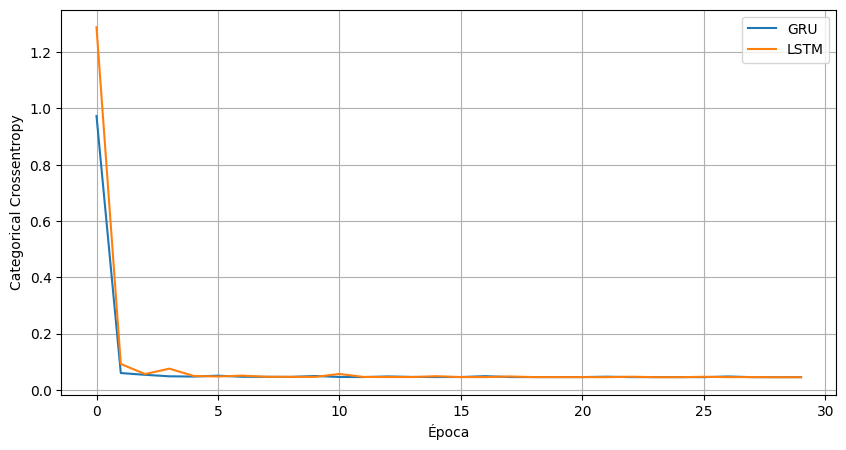

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history_gru.history['loss'],
         label='GRU')

plt.plot(history_lstm.history['loss'],
         label='LSTM')

plt.xlabel('Época')
plt.ylabel('Categorical Crossentropy')
plt.legend()
plt.grid(True)
plt.show()

####  Análise comparativa dos resultados

Embora a arquitetura GRU apresente uma redução de aproximadamente 24,54% no número de parâmetros da camada recorrente em relação à LSTM, essa redução não se traduziu em uma diminuição proporcional do tempo de processamento.

Nas condições experimentais adotadas, o tempo de treinamento da GRU foi apenas 1,17% inferior ao da LSTM, enquanto os tempos de geração de texto foram praticamente iguais.

As duas arquiteturas apresentaram valores finais da função de perda muito semelhantes. Observou-se uma convergência inicial mais rápida da GRU nesta execução, seguida de um comportamento semelhante ao da LSTM nas épocas posteriores.

Esses resultados ilustram que uma menor complexidade estrutural não implica necessariamente uma redução proporcional do tempo de execução, uma vez que este também depende da implementação computacional, das bibliotecas utilizadas, do hardware e do processamento dos dados.

Para o problema considerado, ambas as arquiteturas mostraram-se adequadas à aprendizagem dos padrões presentes no conjunto de treinamento. Entretanto, esses resultados não devem ser generalizados para outros conjuntos de dados ou configurações de hardware, nem constituem uma avaliação da capacidade de generalização dos modelos.